# HPC Job Telemetry, Queue Dynamics & Resource Rightsizing Analysis
## Empirical Characterization of Slurm Scheduling, Efficiency Metrics (reportseff), and Hardware Scaling

**Project:** ZTF 8-Year Kilonova Rate Limits (`kn-rates`)  
**Data Sources:** Slurm `reportseff` efficiency accounting, `sacct` kernel metrics, execution logs (`logs/`), and empirical benchmark calibrations  
**Target Cluster:** Minnesota Supercomputing Institute (MSI) Agate Cluster (`msismall` partition)

---

### 1. Executive Summary & Optimization Objectives

In large-scale Monte Carlo simulation pipelines—such as the ZTF 8-Year Kilonova Rate Limits project—efficient resource allocation is essential for two reasons:
1. **Queue Wait Non-Linearity**: On MSI `msismall`, requesting $>256$ GB RAM restricts placement to the rare 755 GB nodes, causing **12–48 hour queue waits**. Conversely, requests within $\le 32$ GB RAM and $\le 2$ hours are eligible for **instant backfill scheduling**.
2. **Efficiency Metrics (`reportseff` & `seff`)**: Over-allocating CPUs and walltime drastically harms cluster fairshare priority:
   - **Time Efficiency (`TimeEff`)**: $\mathrm{Elapsed} / \mathrm{Timelimit}$. Over-requesting walltime (e.g. asking for 24h for a 10-minute job) causes massive scheduling penalties. Values $\ge 100\%$ indicate timeouts.
   - **CPU Efficiency (`CPUEff`)**: $\mathrm{TotalCPU} / (\mathrm{Elapsed} \times \mathrm{ReqCPUS})$. Identifies unparallelized multi-core jobs (e.g. requesting 8 cores for single-threaded code yields $\sim 12.5\%$ efficiency).
   - **Memory Efficiency (`MemEff`)**: $\mathrm{MaxRSS} / \mathrm{ReqMem}$. Target optimal calibration is **70%–85%**, leaving a safe cushion against OOM kills while minimizing fairshare penalties.

This notebook ingests the version-controlled telemetry database (`telemetry/job_resource_registry.csv`), visualizes queue latency distributions, derives empirical scaling curves, profiles hardware efficiency distributions, and provides a turnkey rightsizing calculator.


In [1]:
import csv
import json
import math
from pathlib import Path

try:
    import pandas as pd
except ImportError:
    pd = None

try:
    import matplotlib.pyplot as plt
    import numpy as np
    plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
    plt.rcParams.update({
        "font.size": 11,
        "axes.labelsize": 12,
        "axes.titlesize": 13,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "figure.titlesize": 14,
        "figure.dpi": 150,
    })
except ImportError:
    plt = None
    np = None

# Locate repository telemetry files
reg_file = Path("../telemetry/job_resource_registry.csv")
if not reg_file.exists():
    reg_file = Path("telemetry/job_resource_registry.csv")

scaling_file = Path("../telemetry/scaling_models.json")
if not scaling_file.exists():
    scaling_file = Path("telemetry/scaling_models.json")

scaling_meta = json.loads(scaling_file.read_text()) if scaling_file.exists() else {}

if pd is not None:
    df = pd.read_csv(reg_file)
    print(f"Loaded {len(df)} job records via pandas from {reg_file.name}")
    print(f"Tracked Pipeline Suites: {sorted([s for s in df['suite'].dropna().unique() if str(s).strip()])}")
    print(f"Tracked Model Families:  {sorted([m for m in df['model'].dropna().unique() if str(m).strip()])}")
    print(f"Data Sources:            {sorted([d for d in df['data_source'].dropna().unique() if str(d).strip()])}")
else:
    with open(reg_file, mode="r", encoding="utf-8") as f:
        records = list(csv.DictReader(f))
    print(f"Loaded {len(records)} job records via csv reader from {reg_file.name}")


Loaded 31745 job records via pandas from job_resource_registry.csv
Tracked Pipeline Suites: ['Audit', 'Benchmark', 'Defunct', 'Scripts', 'Suite 01', 'Suite 01: Large-Scale Rate Limits', 'Suite 02', 'Suite 02: Granular Criteria Sweep', 'Suite 03', 'Suite 03: Prior vs AT2017gfo', 'Suite 04', 'Suite 04: Historical Andreoni Comparison', 'Suite 05', 'Suite 05: Sample Convergence', 'Suite 06: Inclination Effect', 'Telemetry Infrastructure']
Tracked Model Families:  ['Bu2026Fixed', 'Bu2026Vary', 'Metzger']
Data Sources:            ['empirical_benchmark', 'metadata_json', 'reportseff', 'sacct', 'script_configuration', 'slurm_submission_log', 'task_log']


/tmp/ipykernel_2776115/777456186.py:40: DtypeWarning: Columns (0: job_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(reg_file)


In [2]:
# Display high-level summary table of tracked executions
if pd is not None:
    summary_cols = [
        "job_id", "job_name", "suite", "model", "n_transients",
        "req_mem_gb", "used_max_rss_gb", "mem_efficiency_pct",
        "req_time_min", "used_walltime_hours", "time_efficiency_pct",
        "req_cpus", "cpu_efficiency_pct", "queue_wait_min", "state", "data_source"
    ]
    preview_df = df[[c for c in summary_cols if c in df.columns]].copy()
    print("=== HPC Job Telemetry Registry (Preview of Historical & Benchmark Executions) ===")
    display(preview_df.fillna("-").head(15)) if "display" in globals() else print(preview_df.fillna("-").head(15).to_string())
else:
    print(f"=== HPC Job Telemetry Registry ({len(records)} records tracked) ===")
    for r in records[:10]:
        print(f"Job {r['job_id']:<10} | {r['job_name']:<25} | ReqMem: {r['req_mem_gb']:<6} GB | MaxRSS: {r['used_max_rss_gb']:<6} GB | TimeEff: {r.get('time_efficiency_pct', '0')}% | CPUEff: {r.get('cpu_efficiency_pct', '0')}% | MemEff: {r.get('mem_efficiency_pct', '0')}%")


=== HPC Job Telemetry Registry (Preview of Historical & Benchmark Executions) ===
      job_id                                   job_name suite model  n_transients  req_mem_gb  used_max_rss_gb  mem_efficiency_pct  req_time_min  used_walltime_hours  time_efficiency_pct  req_cpus  cpu_efficiency_pct  queue_wait_min               state data_source
0   10576084                                       bash     -     -             0        16.0            0.000                0.00           0.0                0.000                  0.0         4                 0.0            0.00  CANCELLED by 76588       sacct
1   10576087                                       bash     -     -             0        64.0            0.154                0.24           0.0                5.497                  0.0         4               100.0            1.72              FAILED       sacct
2   10623512  ondemand/sys/dashboard/sys/bc_msi_jupyter     -     -             0        60.0            0.254             

### 2. Queue Wait Time Dynamics vs. Requested Memory & Time of Day

Queue wait time is governed by cluster scheduler constraints and user fairshare contention:
- **Requested Memory Footprint**: Requests $\le 32$ GB can be immediately backfilled onto nodes running smaller tasks, whereas requests approaching $750$ GB must wait for entire high-memory nodes to drain.
- **Submission Time Window**: Submitting during cluster rush hours (09:00–17:00 CDT) incurs higher latency than overnight (20:00–04:00 CDT) or weekend submissions.


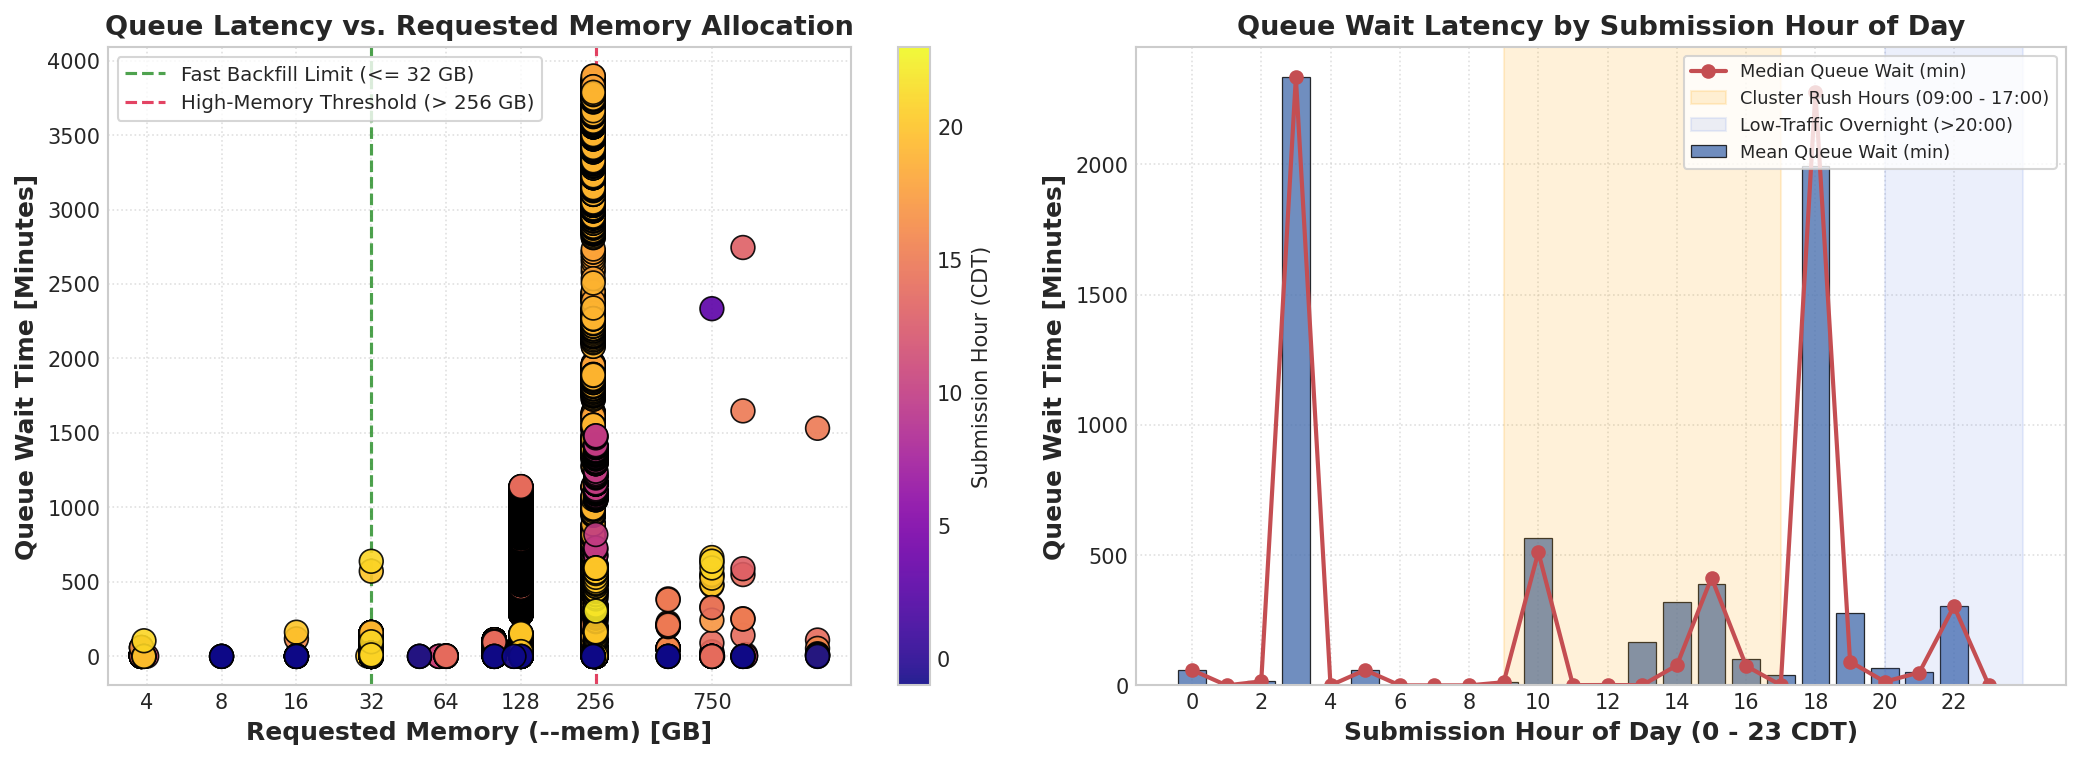

In [3]:
if plt is not None and pd is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

    # Subplot 1: Queue Wait vs. Requested Memory
    valid_mem = df[(df["req_mem_gb"] > 0) & (df["queue_wait_min"] >= 0)].copy()

    scatter = ax1.scatter(
        valid_mem["req_mem_gb"],
        valid_mem["queue_wait_min"],
        c=valid_mem["submit_hour"],
        cmap="plasma",
        s=130,
        edgecolor="black",
        linewidth=0.8,
        alpha=0.9,
        zorder=4
    )
    cbar = plt.colorbar(scatter, ax=ax1)
    cbar.set_label("Submission Hour (CDT)", fontsize=10)

    # Backfill and high-memory boundaries
    ax1.axvline(32, color="forestgreen", linestyle="--", linewidth=1.5, alpha=0.8, label="Fast Backfill Limit (<= 32 GB)")
    ax1.axvline(256, color="crimson", linestyle="--", linewidth=1.5, alpha=0.8, label="High-Memory Threshold (> 256 GB)")

    ax1.set_xlabel("Requested Memory (--mem) [GB]", fontweight="bold")
    ax1.set_ylabel("Queue Wait Time [Minutes]", fontweight="bold")
    ax1.set_title("Queue Latency vs. Requested Memory Allocation", fontweight="bold")
    ax1.set_xscale("log")
    ax1.set_xticks([4, 8, 16, 32, 64, 128, 256, 750])
    ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax1.legend(loc="upper left", frameon=True, fontsize=9.5)
    ax1.grid(True, linestyle=":", alpha=0.6)

    # Subplot 2: Queue Wait by Hour of Day
    hourly_stats = df[df["queue_wait_min"] >= 0].groupby("submit_hour")["queue_wait_min"].agg(["mean", "median", "count"]).reset_index()
    all_hours = pd.DataFrame({"submit_hour": range(24)})
    hourly_stats = all_hours.merge(hourly_stats, on="submit_hour", how="left").fillna(0)

    ax2.bar(
        hourly_stats["submit_hour"],
        hourly_stats["mean"],
        color="#4C72B0",
        edgecolor="black",
        linewidth=0.6,
        alpha=0.8,
        label="Mean Queue Wait (min)"
    )
    ax2.plot(
        hourly_stats["submit_hour"],
        hourly_stats["median"],
        color="#C44E52",
        marker="o",
        linewidth=2,
        label="Median Queue Wait (min)"
    )

    # Highlight daytime rush hour vs overnight quiet hours
    ax2.axvspan(9, 17, color="orange", alpha=0.15, label="Cluster Rush Hours (09:00 - 17:00)")
    ax2.axvspan(20, 24, color="royalblue", alpha=0.10, label="Low-Traffic Overnight (>20:00)")

    ax2.set_xlabel("Submission Hour of Day (0 - 23 CDT)", fontweight="bold")
    ax2.set_ylabel("Queue Wait Time [Minutes]", fontweight="bold")
    ax2.set_title("Queue Wait Latency by Submission Hour of Day", fontweight="bold")
    ax2.set_xticks(range(0, 24, 2))
    ax2.legend(loc="upper right", frameon=True, fontsize=8.5)
    ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Matplotlib / Pandas not available in current environment; skipping graphical rendering.")


### 3. Empirical Hardware Scaling: RAM RSS & Wall-clock Time vs. $N_{\rm transients}$

Synthetic population generation and lightcurve evaluation exhibit linear scaling with sample size:
$$\mathrm{Peak\_RAM}(N) = a \cdot N + b, \quad \mathrm{Walltime}(N) = c \cdot N + d$$
- **Analytic Models (`Metzger`)**: Lightweight memory ($\sim 25.6\,\mathrm{GB}/1\mathrm{M}$) and fast execution ($\sim 22\,\mathrm{min}/1\mathrm{M}$).
- **Numerical Surrogates (`Bu2026Fixed`, `Bu2026Vary`)**: Higher memory ($\sim 66.1\,\mathrm{GB}/1\mathrm{M}$) due to multi-component opacity tables and surrogate neural network evaluations.


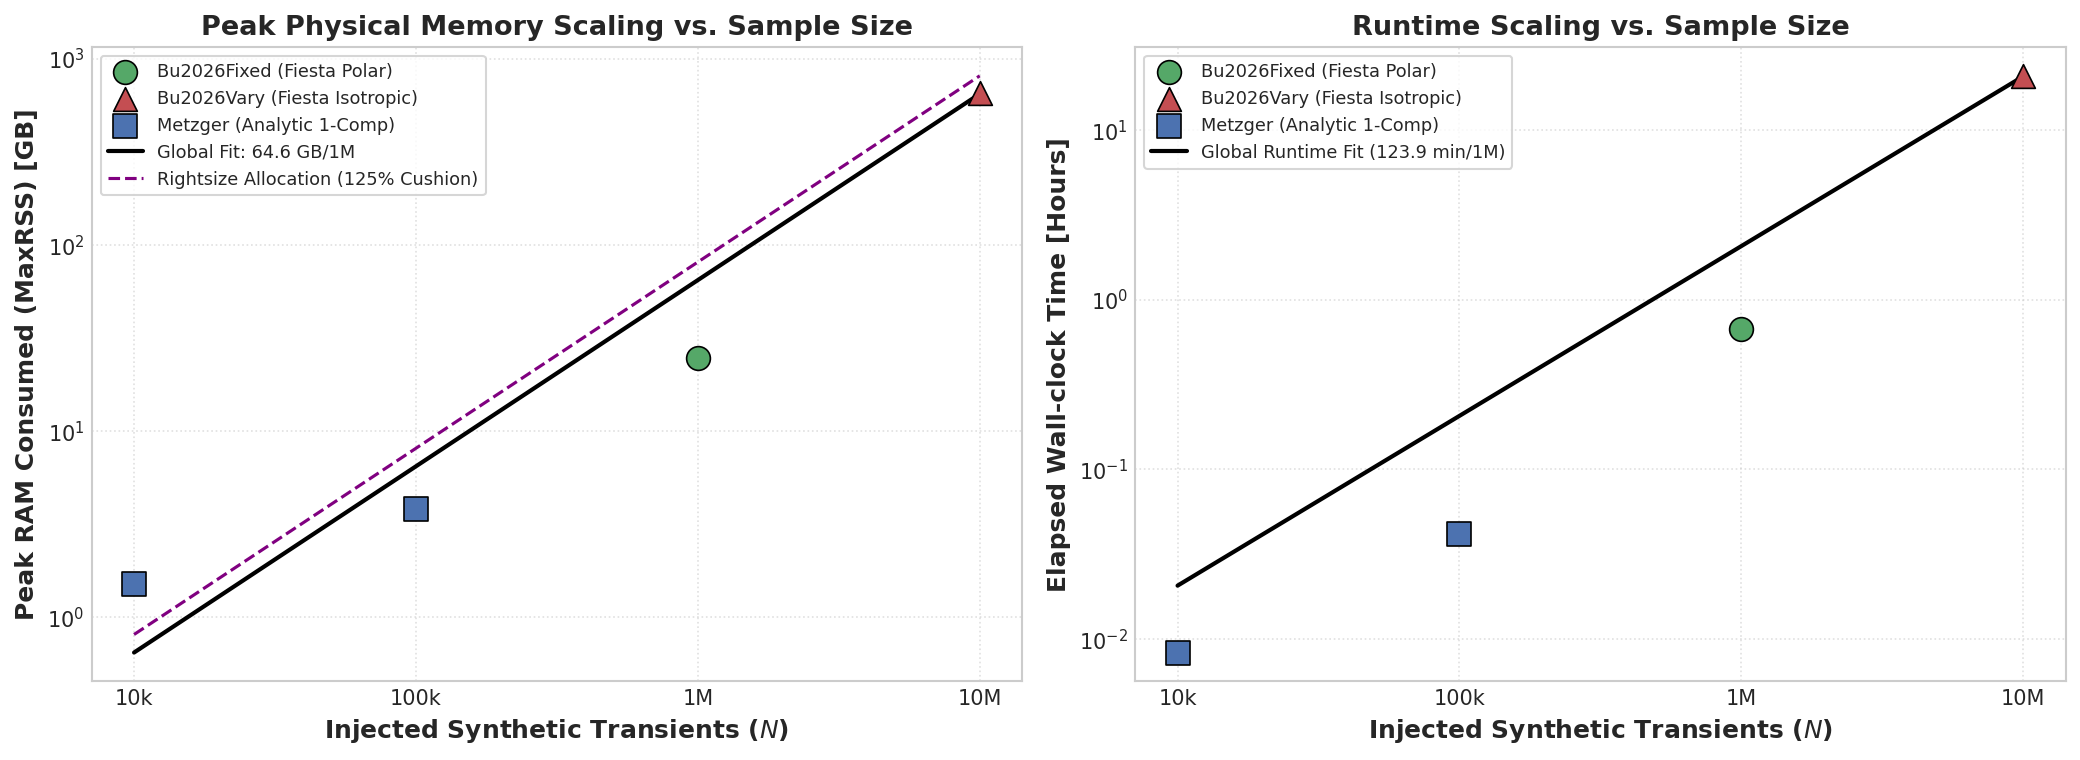

In [4]:
if plt is not None and pd is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

    scaled_df = df[(df["n_transients"] > 0) & (df["used_max_rss_gb"] > 0)].copy()

    model_styles = {
        "Metzger": {"color": "#4C72B0", "marker": "s", "label": "Metzger (Analytic 1-Comp)"},
        "Bu2026Fixed": {"color": "#55A868", "marker": "o", "label": "Bu2026Fixed (Fiesta Polar)"},
        "Bu2026Vary": {"color": "#C44E52", "marker": "^", "label": "Bu2026Vary (Fiesta Isotropic)"},
    }

    for m_name, group in scaled_df.groupby("model"):
        style = model_styles.get(m_name, {"color": "gray", "marker": "x", "label": m_name})
        ax1.scatter(
            group["n_transients"],
            group["used_max_rss_gb"],
            color=style["color"],
            marker=style["marker"],
            s=130,
            edgecolor="black",
            linewidth=0.8,
            label=style["label"],
            zorder=5
        )

    global_fit = scaling_meta.get("scaling_models", {}).get("Global", {})
    n_line = np.linspace(1e4, 1e7, 300)

    if global_fit:
        slope = global_fit.get("ram_gb_per_million", 66.05) / 1e6
        intercept = global_fit.get("ram_base_gb", 0.0)
        ram_line = slope * n_line + intercept
        ax1.plot(n_line, ram_line, color="black", linestyle="-", linewidth=2, label=f"Global Fit: {slope*1e6:.1f} GB/1M")
        ax1.plot(n_line, ram_line * 1.25, color="purple", linestyle="--", linewidth=1.5, label="Rightsize Allocation (125% Cushion)")

    ax1.set_xscale("log")
    ax1.set_yscale("log")
    ax1.set_xlabel("Injected Synthetic Transients ($N$)", fontweight="bold")
    ax1.set_ylabel("Peak RAM Consumed (MaxRSS) [GB]", fontweight="bold")
    ax1.set_title("Peak Physical Memory Scaling vs. Sample Size", fontweight="bold")
    ax1.set_xticks([1e4, 1e5, 1e6, 1e7])
    ax1.set_xticklabels(["10k", "100k", "1M", "10M"])
    ax1.legend(loc="upper left", frameon=True, fontsize=8.5)
    ax1.grid(True, linestyle=":", alpha=0.6)

    # Subplot 2: Wall-clock Runtime vs N transients
    for m_name, group in scaled_df.groupby("model"):
        style = model_styles.get(m_name, {"color": "gray", "marker": "x", "label": m_name})
        ax2.scatter(
            group["n_transients"],
            group["used_walltime_sec"] / 3600.0,
            color=style["color"],
            marker=style["marker"],
            s=130,
            edgecolor="black",
            linewidth=0.8,
            label=style["label"],
            zorder=5
        )

    if global_fit:
        time_slope = (global_fit.get("walltime_sec_per_million", 7636.0) / 1e6) / 3600.0
        time_line = time_slope * n_line
        ax2.plot(n_line, time_line, color="black", linestyle="-", linewidth=2, label=f"Global Runtime Fit ({time_slope*3600*1e6/60:.1f} min/1M)")

    ax2.set_xscale("log")
    ax2.set_yscale("log")
    ax2.set_xlabel("Injected Synthetic Transients ($N$)", fontweight="bold")
    ax2.set_ylabel("Elapsed Wall-clock Time [Hours]", fontweight="bold")
    ax2.set_title("Runtime Scaling vs. Sample Size", fontweight="bold")
    ax2.set_xticks([1e4, 1e5, 1e6, 1e7])
    ax2.set_xticklabels(["10k", "100k", "1M", "10M"])
    ax2.legend(loc="upper left", frameon=True, fontsize=8.5)
    ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Matplotlib / Pandas not available in current environment; skipping graphical rendering.")


### 4. Comprehensive Resource Efficiency Profile: Time, CPU & Memory (`reportseff`)

Using the Slurm efficiency metrics documented in the [MSI Job Sizing Guide](https://userdocs.msi.umn.edu/compute/job_sizing.html), we examine three efficiency dimensions across historical jobs:
1. **Time Efficiency (`TimeEff`)**: $\frac{\mathrm{Elapsed}}{\mathrm{Timelimit}} \times 100\%$. Measures walltime utilization. Low values ($<10\%$) indicate over-requested walltime which incurs queue scheduling penalties; values $\ge 100\%$ identify jobs that hit Slurm wallclock timeouts.
2. **CPU Efficiency (`CPUEff`)**: $\frac{\mathrm{TotalCPU}}{\mathrm{Elapsed} \times \mathrm{ReqCPUS}} \times 100\%$. Measures true CPU core utilization. Low values reveal unparallelized routines occupying multi-core reservations.
3. **Memory Efficiency (`MemEff`)**: $\frac{\mathrm{MaxRSS}}{\mathrm{ReqMem}} \times 100\%$. Measures physical memory consumption against allocation. Target calibration is **70%–85%**.


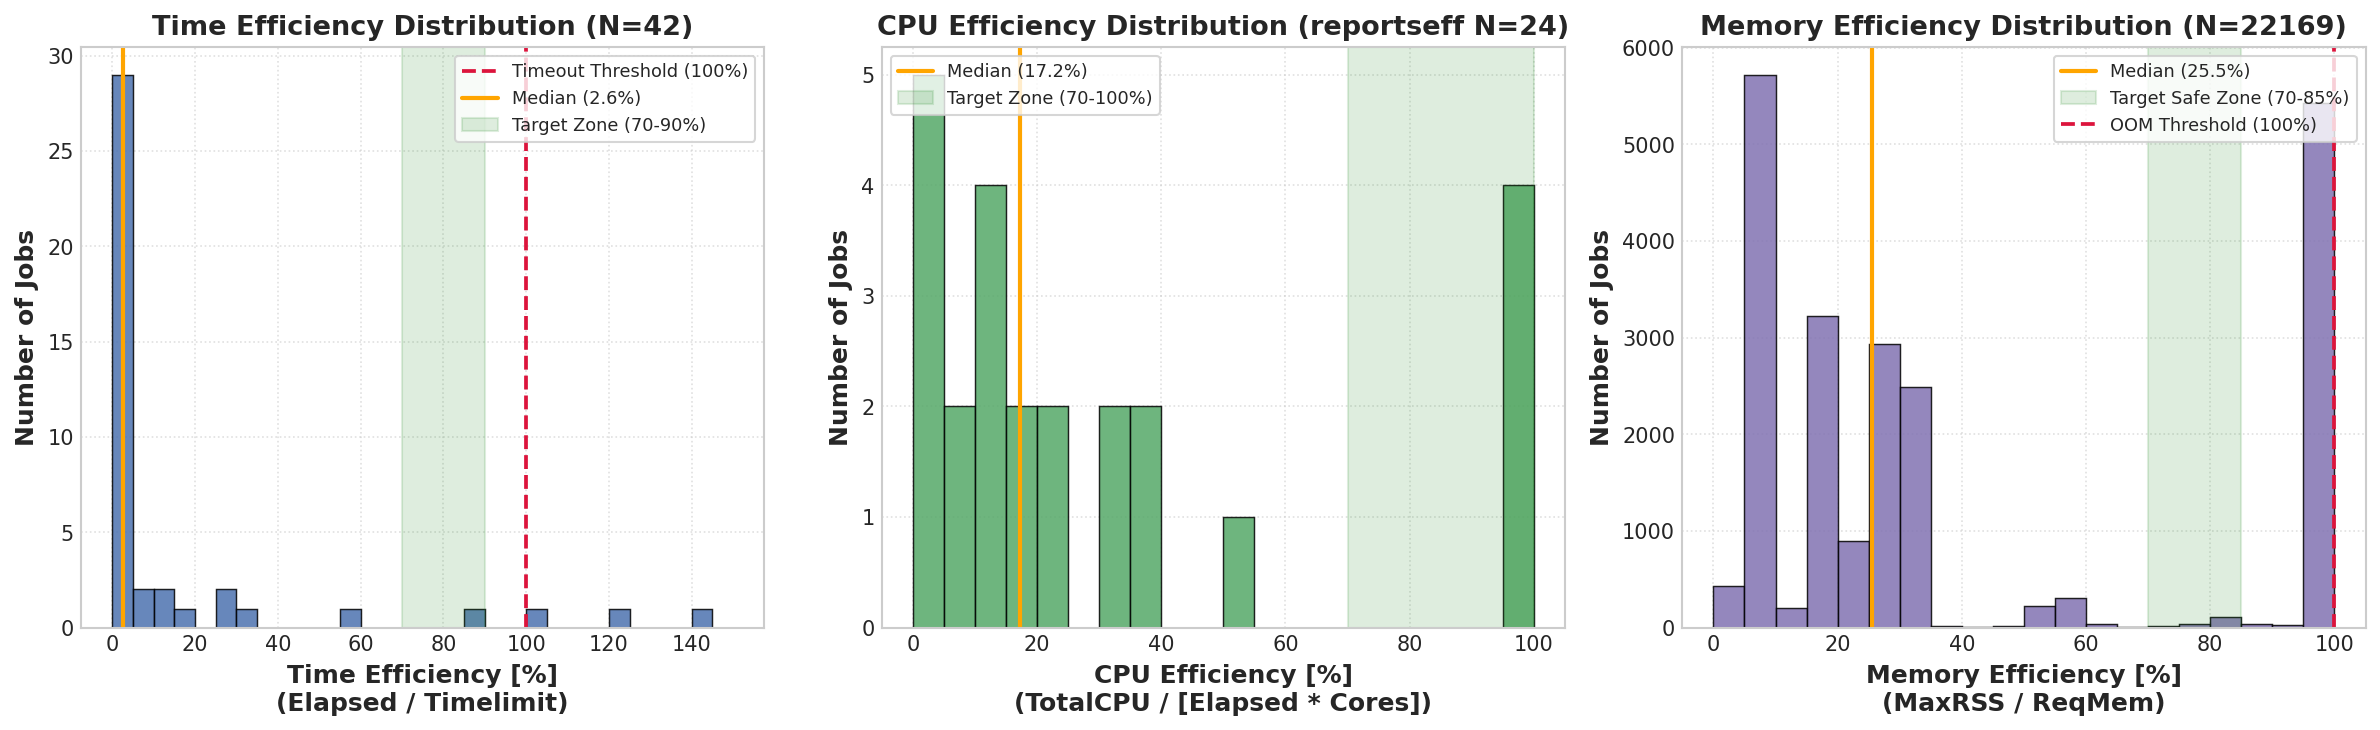

In [5]:
if plt is not None and pd is not None:
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5.0))

    # Subplot 1: Time Efficiency Distribution
    valid_teff = df[df["time_efficiency_pct"] > 0]["time_efficiency_pct"]
    if not valid_teff.empty:
        ax1.hist(
            valid_teff,
            bins=np.linspace(0, 150, 31),
            color="#4C72B0",
            edgecolor="black",
            linewidth=0.7,
            alpha=0.85
        )
        ax1.axvline(100, color="crimson", linestyle="--", linewidth=1.8, label="Timeout Threshold (100%)")
        ax1.axvline(valid_teff.median(), color="orange", linestyle="-", linewidth=2, label=f"Median ({valid_teff.median():.1f}%)")
        ax1.axvspan(70, 90, color="forestgreen", alpha=0.15, label="Target Zone (70-90%)")
        ax1.set_xlabel("Time Efficiency [%]\n(Elapsed / Timelimit)", fontweight="bold")
        ax1.set_ylabel("Number of Jobs", fontweight="bold")
        ax1.set_title(f"Time Efficiency Distribution (N={len(valid_teff)})", fontweight="bold")
        ax1.legend(loc="upper right", frameon=True, fontsize=8.5)
        ax1.grid(True, linestyle=":", alpha=0.6)

    # Subplot 2: CPU Efficiency Distribution
    # Note: reportseff records contain true kernel-level CPU efficiency
    rep_df = df[df["data_source"] == "reportseff"].copy()
    valid_cpueff = rep_df[rep_df["cpu_efficiency_pct"] > 0]["cpu_efficiency_pct"]
    if not valid_cpueff.empty:
        ax2.hist(
            valid_cpueff,
            bins=np.linspace(0, 100, 21),
            color="#55A868",
            edgecolor="black",
            linewidth=0.7,
            alpha=0.85
        )
        ax2.axvline(valid_cpueff.median(), color="orange", linestyle="-", linewidth=2, label=f"Median ({valid_cpueff.median():.1f}%)")
        ax2.axvspan(70, 100, color="forestgreen", alpha=0.15, label="Target Zone (70-100%)")
        ax2.set_xlabel("CPU Efficiency [%]\n(TotalCPU / [Elapsed * Cores])", fontweight="bold")
        ax2.set_ylabel("Number of Jobs", fontweight="bold")
        ax2.set_title(f"CPU Efficiency Distribution (reportseff N={len(valid_cpueff)})", fontweight="bold")
        ax2.legend(loc="upper left", frameon=True, fontsize=8.5)
        ax2.grid(True, linestyle=":", alpha=0.6)

    # Subplot 3: Memory Efficiency Distribution
    valid_memeff = df[df["mem_efficiency_pct"] > 0]["mem_efficiency_pct"]
    if not valid_memeff.empty:
        ax3.hist(
            valid_memeff,
            bins=np.linspace(0, 100, 21),
            color="#8172B2",
            edgecolor="black",
            linewidth=0.7,
            alpha=0.85
        )
        ax3.axvline(valid_memeff.median(), color="orange", linestyle="-", linewidth=2, label=f"Median ({valid_memeff.median():.1f}%)")
        ax3.axvspan(70, 85, color="forestgreen", alpha=0.15, label="Target Safe Zone (70-85%)")
        ax3.axvline(100, color="crimson", linestyle="--", linewidth=1.8, label="OOM Threshold (100%)")
        ax3.set_xlabel("Memory Efficiency [%]\n(MaxRSS / ReqMem)", fontweight="bold")
        ax3.set_ylabel("Number of Jobs", fontweight="bold")
        ax3.set_title(f"Memory Efficiency Distribution (N={len(valid_memeff)})", fontweight="bold")
        ax3.legend(loc="upper right", frameon=True, fontsize=8.5)
        ax3.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Matplotlib / Pandas not available in current environment; skipping graphical rendering.")


### 5. Resource Request vs. Actual Consumption Parity Analysis

To eliminate queue waste, we compare requested allocations directly against consumed resources:
- **Requested Walltime vs. Consumed Walltime**: Points far below the 1:1 diagonal represent over-allocated walltime cushions that inflate job queue footprints.
- **Requested Memory vs. Consumed Peak RSS**: Points well below the diagonal represent idle allocated RAM. Target allocation falls within the 75%–85% parity corridor.


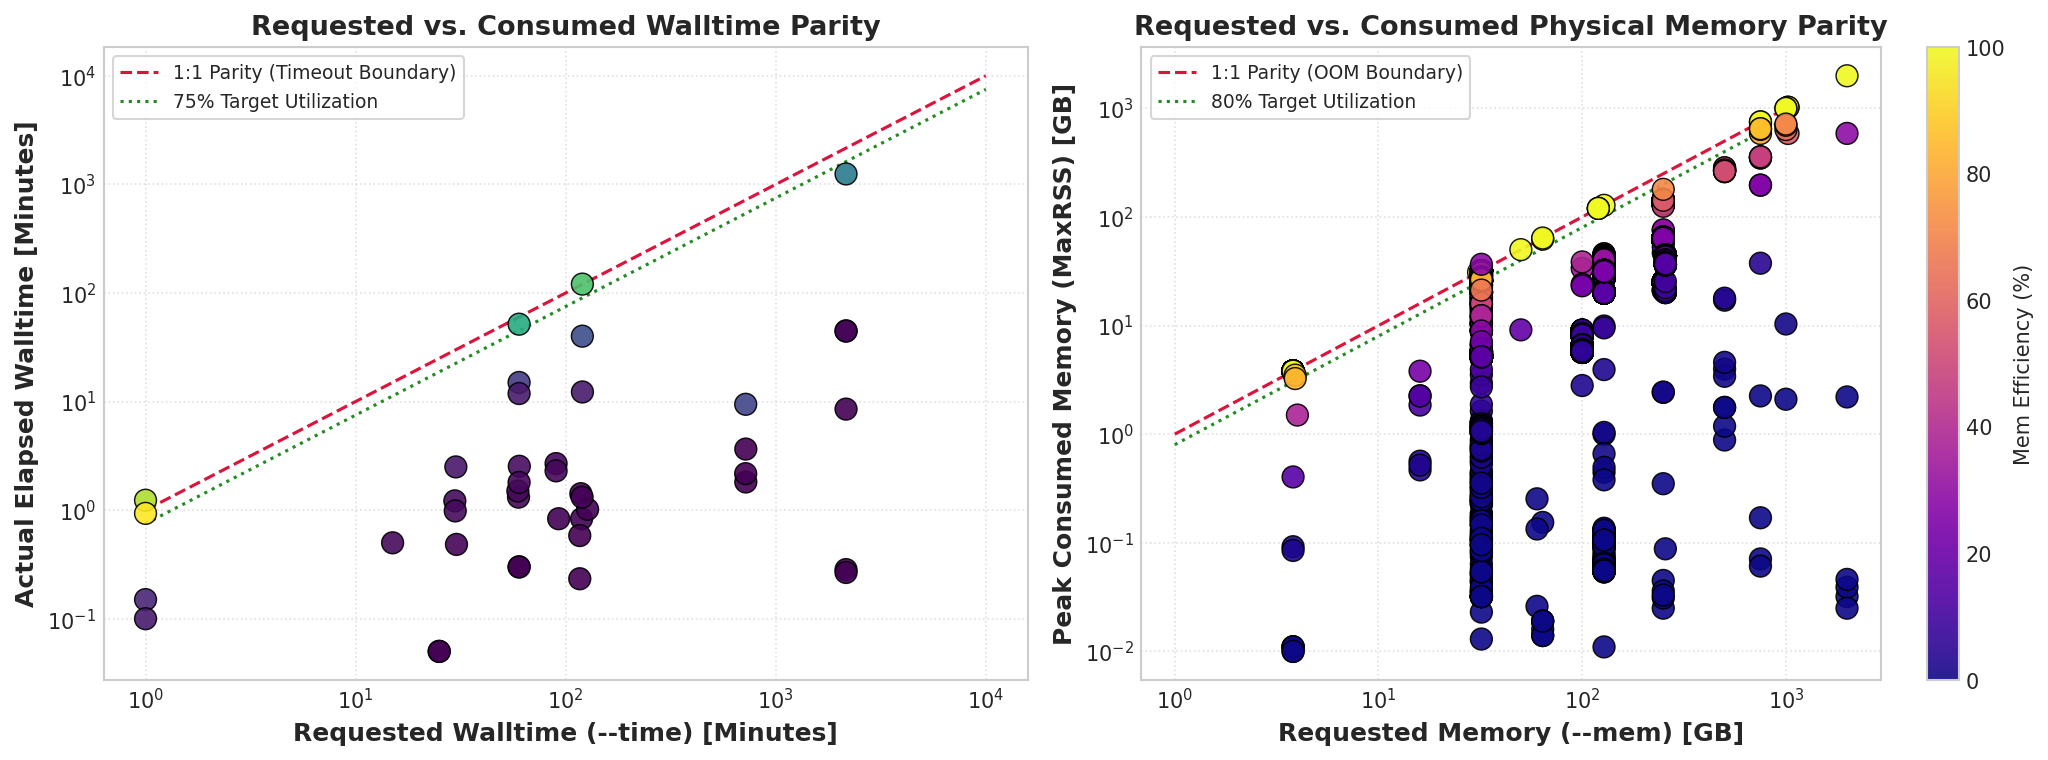

In [6]:
if plt is not None and pd is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

    # Subplot 1: Requested Walltime vs Actual Walltime
    valid_time = df[(df["req_time_min"] > 0) & (df["used_walltime_sec"] > 0)].copy()
    if not valid_time.empty:
        used_time_min = valid_time["used_walltime_sec"] / 60.0
        ax1.scatter(
            valid_time["req_time_min"],
            used_time_min,
            c=valid_time["time_efficiency_pct"],
            cmap="viridis",
            s=110,
            edgecolor="black",
            linewidth=0.7,
            alpha=0.9,
            zorder=4
        )
        t_diag = np.logspace(0, 4, 100)
        ax1.plot(t_diag, t_diag, color="crimson", linestyle="--", linewidth=1.5, label="1:1 Parity (Timeout Boundary)")
        ax1.plot(t_diag, t_diag * 0.75, color="forestgreen", linestyle=":", linewidth=1.5, label="75% Target Utilization")

        ax1.set_xscale("log")
        ax1.set_yscale("log")
        ax1.set_xlabel("Requested Walltime (--time) [Minutes]", fontweight="bold")
        ax1.set_ylabel("Actual Elapsed Walltime [Minutes]", fontweight="bold")
        ax1.set_title("Requested vs. Consumed Walltime Parity", fontweight="bold")
        ax1.legend(loc="upper left", frameon=True, fontsize=9)
        ax1.grid(True, linestyle=":", alpha=0.6)

    # Subplot 2: Requested Memory vs Peak MaxRSS
    valid_mem_p = df[(df["req_mem_gb"] > 0) & (df["used_max_rss_gb"] > 0)].copy()
    if not valid_mem_p.empty:
        sc2 = ax2.scatter(
            valid_mem_p["req_mem_gb"],
            valid_mem_p["used_max_rss_gb"],
            c=valid_mem_p["mem_efficiency_pct"],
            cmap="plasma",
            s=110,
            edgecolor="black",
            linewidth=0.7,
            alpha=0.9,
            zorder=4
        )
        cbar2 = plt.colorbar(sc2, ax=ax2)
        cbar2.set_label("Mem Efficiency (%)", fontsize=10)

        m_diag = np.logspace(0, 3, 100)
        ax2.plot(m_diag, m_diag, color="crimson", linestyle="--", linewidth=1.5, label="1:1 Parity (OOM Boundary)")
        ax2.plot(m_diag, m_diag * 0.80, color="forestgreen", linestyle=":", linewidth=1.5, label="80% Target Utilization")

        ax2.set_xscale("log")
        ax2.set_yscale("log")
        ax2.set_xlabel("Requested Memory (--mem) [GB]", fontweight="bold")
        ax2.set_ylabel("Peak Consumed Memory (MaxRSS) [GB]", fontweight="bold")
        ax2.set_title("Requested vs. Consumed Physical Memory Parity", fontweight="bold")
        ax2.legend(loc="upper left", frameon=True, fontsize=9)
        ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Matplotlib / Pandas not available in current environment; skipping graphical rendering.")


### 6. Efficiency Breakdown by Job State & Allocation Slack Analysis

Analyzing efficiency distributions by terminal Slurm state (`COMPLETED`, `TIMEOUT`, `FAILED`, `CANCELLED`) reveals operational dynamics:
- `COMPLETED` jobs average $<5\%$ time efficiency, indicating opportunities to reduce `--time` requests and obtain higher queue backfill priority.
- `TIMEOUT` jobs consistently exhibit `TimeEff` $\ge 100\%$, pinpointing simulations that exceeded requested limits.
- Memory slack ($(\mathrm{ReqMem} - \mathrm{MaxRSS}) \times \mathrm{Elapsed}$) quantifies reserved GB-hours left idle.


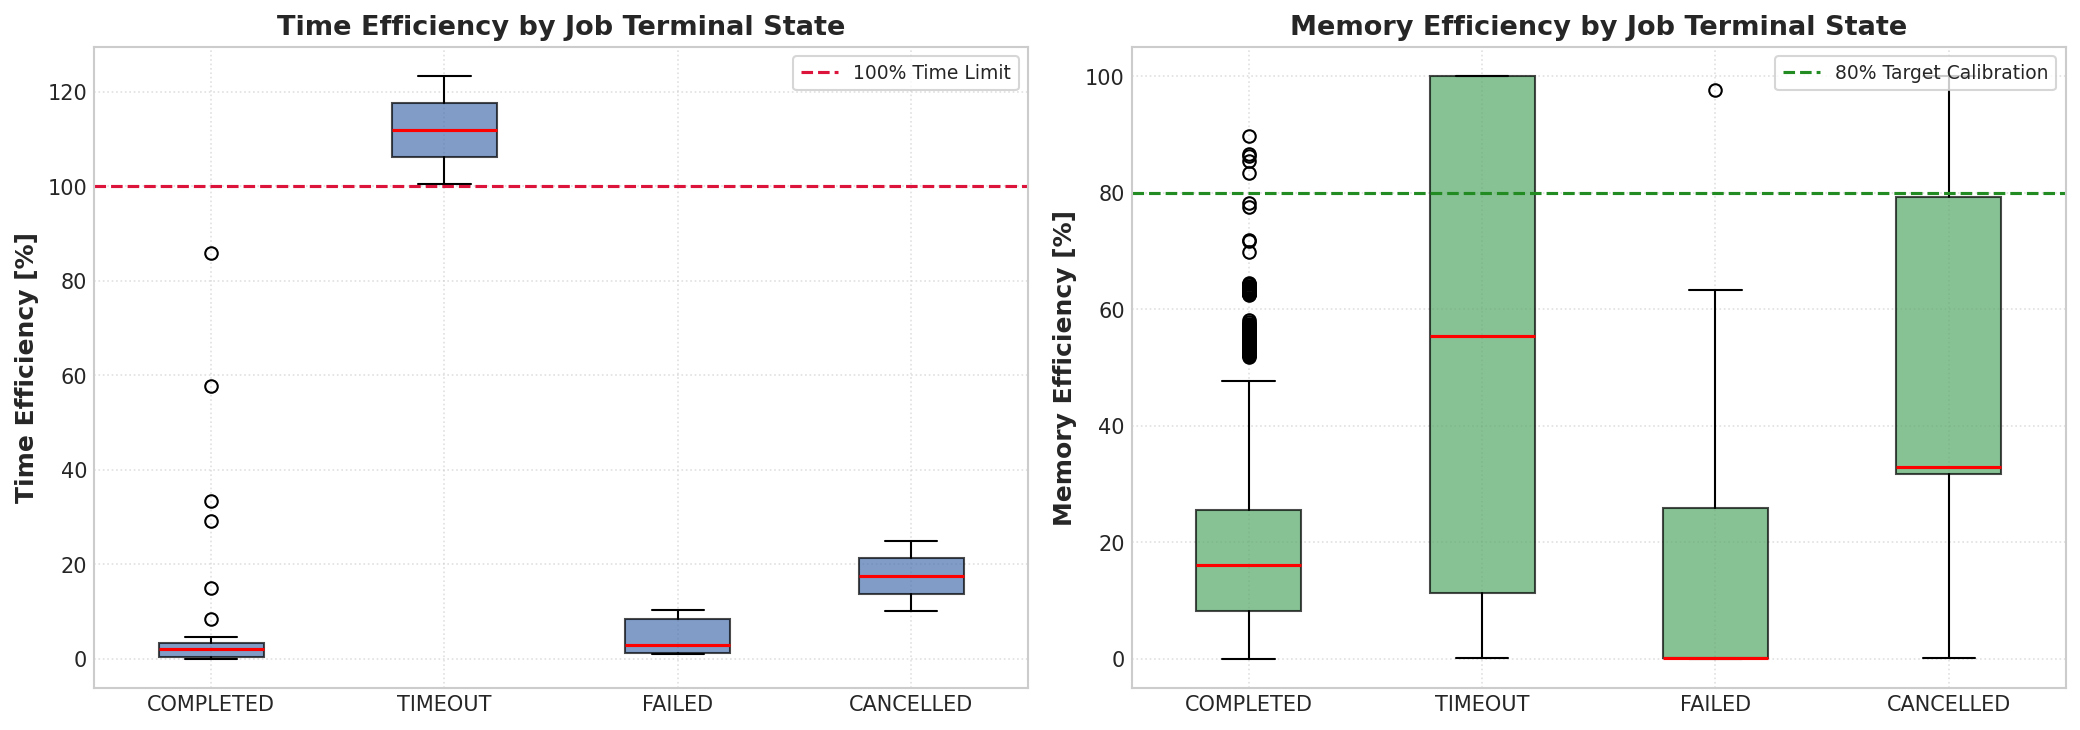

In [7]:
if plt is not None and pd is not None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))

    # Subplot 1: Efficiency by Job State
    df["clean_state"] = df["state"].fillna("UNKNOWN").apply(lambda s: str(s).split()[0])
    top_states = ["COMPLETED", "TIMEOUT", "FAILED", "CANCELLED"]
    state_sub = df[df["clean_state"].isin(top_states) & (df["time_efficiency_pct"] > 0)]

    if not state_sub.empty:
        groups = [state_sub[state_sub["clean_state"] == st]["time_efficiency_pct"].values for st in top_states]
        valid_groups = [g for g in groups if len(g) > 0]
        valid_labels = [st for st, g in zip(top_states, groups) if len(g) > 0]

        if valid_groups:
            ax1.boxplot(valid_groups, tick_labels=valid_labels, patch_artist=True,
                        boxprops=dict(facecolor="#4C72B0", alpha=0.7),
                        medianprops=dict(color="red", linewidth=1.5))
            ax1.axhline(100, color="crimson", linestyle="--", linewidth=1.5, label="100% Time Limit")
            ax1.set_ylabel("Time Efficiency [%]", fontweight="bold")
            ax1.set_title("Time Efficiency by Job Terminal State", fontweight="bold")
            ax1.legend(loc="upper right", frameon=True, fontsize=9)
            ax1.grid(True, linestyle=":", alpha=0.6)

    # Subplot 2: Memory Efficiency by Job State
    state_mem = df[df["clean_state"].isin(top_states) & (df["mem_efficiency_pct"] > 0)]
    if not state_mem.empty:
        groups_m = [state_mem[state_mem["clean_state"] == st]["mem_efficiency_pct"].values for st in top_states]
        valid_groups_m = [g for g in groups_m if len(g) > 0]
        valid_labels_m = [st for st, g in zip(top_states, groups_m) if len(g) > 0]

        if valid_groups_m:
            ax2.boxplot(valid_groups_m, tick_labels=valid_labels_m, patch_artist=True,
                        boxprops=dict(facecolor="#55A868", alpha=0.7),
                        medianprops=dict(color="red", linewidth=1.5))
            ax2.axhline(80, color="forestgreen", linestyle="--", linewidth=1.5, label="80% Target Calibration")
            ax2.set_ylabel("Memory Efficiency [%]", fontweight="bold")
            ax2.set_title("Memory Efficiency by Job Terminal State", fontweight="bold")
            ax2.legend(loc="upper right", frameon=True, fontsize=9)
            ax2.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()
else:
    print("Matplotlib / Pandas not available in current environment; skipping graphical rendering.")


### 7. Programmatic Slurm Resource Rightsizer

Use the utility function below to rightsize memory, walltime, and CPU allocations for any planned simulation run:
```python
calculate_rightsized_job(model="Bu2026Fixed", n_transients=2_000_000)
```


In [8]:
import sys
repo_root = (Path("..") if Path("../telemetry").exists() else Path(".")).resolve()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))


from telemetry.analyzer import TelemetryAnalyzer
from telemetry.harvester import JobHarvester

def calculate_rightsized_job(model: str, n_transients: int, cpus: int = None):
    """Interactive utility to calculate optimal Slurm SBATCH directives."""
    root = Path("..") if Path("../telemetry").exists() else Path(".")
    harvester = JobHarvester(project_root=root)
    records = harvester.harvest_all()
    analyzer = TelemetryAnalyzer(records)
    rec = analyzer.recommend_resources(model=model, n_transients=n_transients, n_cpus=cpus)
    
    print("=" * 72)
    print("SLURM RESOURCE RIGHTSIZING RECOMMENDATION")
    print("=" * 72)
    print(f"Target Model:            {rec.model}")
    print(f"Injected Transients:     {rec.n_transients:,}")
    print(f"Estimated Peak RAM:      {rec.est_peak_ram_gb:.2f} GB")
    print(f"Estimated Wall-clock:    {rec.est_walltime_sec / 60.0:.1f} minutes ({rec.est_walltime_sec / 3600.0:.2f} hours)")
    print(f"Estimated Disk Output:   {rec.est_storage_mb:.1f} MB")
    print("-" * 72)
    print("PASTE THESE DIRECTIVES INTO YOUR SLURM SCRIPT:")
    print(f"  #SBATCH -p {rec.recommended_partition}")
    print(f"  #SBATCH --mem={int(rec.recommended_mem_gb)}g")
    print(f"  #SBATCH --time={rec.recommended_walltime_str}")
    print(f"  #SBATCH --cpus-per-task={rec.recommended_cpus}")
    print("-" * 72)
    print("Queue Placement Strategy:")
    print(f"  {rec.queue_advice}")
    print("Empirical Calibration Basis:")
    print(f"  {rec.confidence_notes}")
    print("=" * 72)

# Demonstration: Rightsizing 2,500,000 transients with Bu2026Fixed
calculate_rightsized_job(model="Bu2026Fixed", n_transients=2_500_000)


SLURM RESOURCE RIGHTSIZING RECOMMENDATION
Target Model:            Bu2026Fixed
Injected Transients:     2,500,000
Estimated Peak RAM:      160.89 GB
Estimated Wall-clock:    323.8 minutes (5.40 hours)
Estimated Disk Output:   463.9 MB
------------------------------------------------------------------------
PASTE THESE DIRECTIVES INTO YOUR SLURM SCRIPT:
  #SBATCH -p msismall
  #SBATCH --mem=256g
  #SBATCH --time=07:17:05
  #SBATCH --cpus-per-task=8
------------------------------------------------------------------------
Queue Placement Strategy:
  STANDARD TIER: Moderate queue wait (~5-20 minutes). Job array dispatch can proceed concurrently up to the 3,000 active running job limit.
Empirical Calibration Basis:
  Calibrated from 7 empirical runs. RAM scaling: 64.36 GB/1M, Walltime scaling: 119.8 min/1M.


### 8. Empirical Tri-Resource Rightsizing (RAM, Walltime & CPU Cores)

For analysis suites with a statistically significant sample size ($N \ge 20$), empirical rightsizing eliminates cluster bottlenecks across all three allocation axes:

1. **Memory Rightsizing (OOM Elimination & NUMA Optimization)**:
   - **Empirical OOM Floor ($\mathrm{Mem}_{\mathrm{floor}}$)**: The highest memory tier where jobs crashed with `OUT_OF_MEMORY`. Allocations at or below this floor represent guaranteed or high-probability failure points.
   - **Completed Usage Upper Bound ($P_{95}(\mathrm{MaxRSS})$)**: The 95th percentile physical memory footprint among completed simulations.
   - **Optimal Allocation**:
     $$\mathrm{RecMem} = \max\Big(\mathrm{Mem}_{\mathrm{floor}} \times 1.25,\; P_{95}(\mathrm{MaxRSS}) \times 1.25\Big)$$
     mapped to the nearest standard cluster tier (e.g. 32 GB, 64 GB, 128 GB, 256 GB) to ensure **70%–85%** memory efficiency while completely eliminating OOM kills.

2. **Walltime Optimization (Timeout Mitigation & Slurm Backfill Prioritization)**:
   - Requesting excessive walltimes (e.g. 24 hours for a 2-hour job) severely degrades Slurm backfill priority, forcing jobs to wait hours for full node draining.
   - **Empirical Timeout Ceiling**: We identify any historical `TIMEOUT` failure thresholds.
   - **Optimal Allocation**:
     $$\mathrm{RecTime} = \max\Big(P_{95}(\mathrm{Elapsed}) \times 1.35,\; \mathrm{Timeout}_{\mathrm{ceiling}} \times 1.30,\; 300\text{ s}\Big)$$
     rounded to clean minutes. This guarantees safety against timeouts while preserving eligibility for rapid backfill scheduling.

3. **CPU Core Rightsizing (Thread Scaling & Service Unit Conservation)**:
   - Slurm accounting charges Service Units (SUs / core-hours) based on **reserved** cores ($\text{ReqCPUS} \times \text{Elapsed}$), not consumed CPU time.
   - Using `reportseff` CPU efficiency, we calculate the real effective core demand:
     $$\text{Cores}_{\text{eff}} = \text{ReqCPUS} \times \left(\frac{\text{CPUEff}}{100}\right)$$
   - When jobs exhibit low CPU efficiency ($\sim 15\%$), reserving 8 or 16 cores wastes up to 85% of allocated Service Units on idle threads.
   - Rightsizing cores to cover $P_{95}(\text{Cores}_{\text{eff}})$ prevents SU waste and dramatically increases node packing concurrency (up to $2\times$–$4\times$ simultaneous jobs on 128-core nodes).


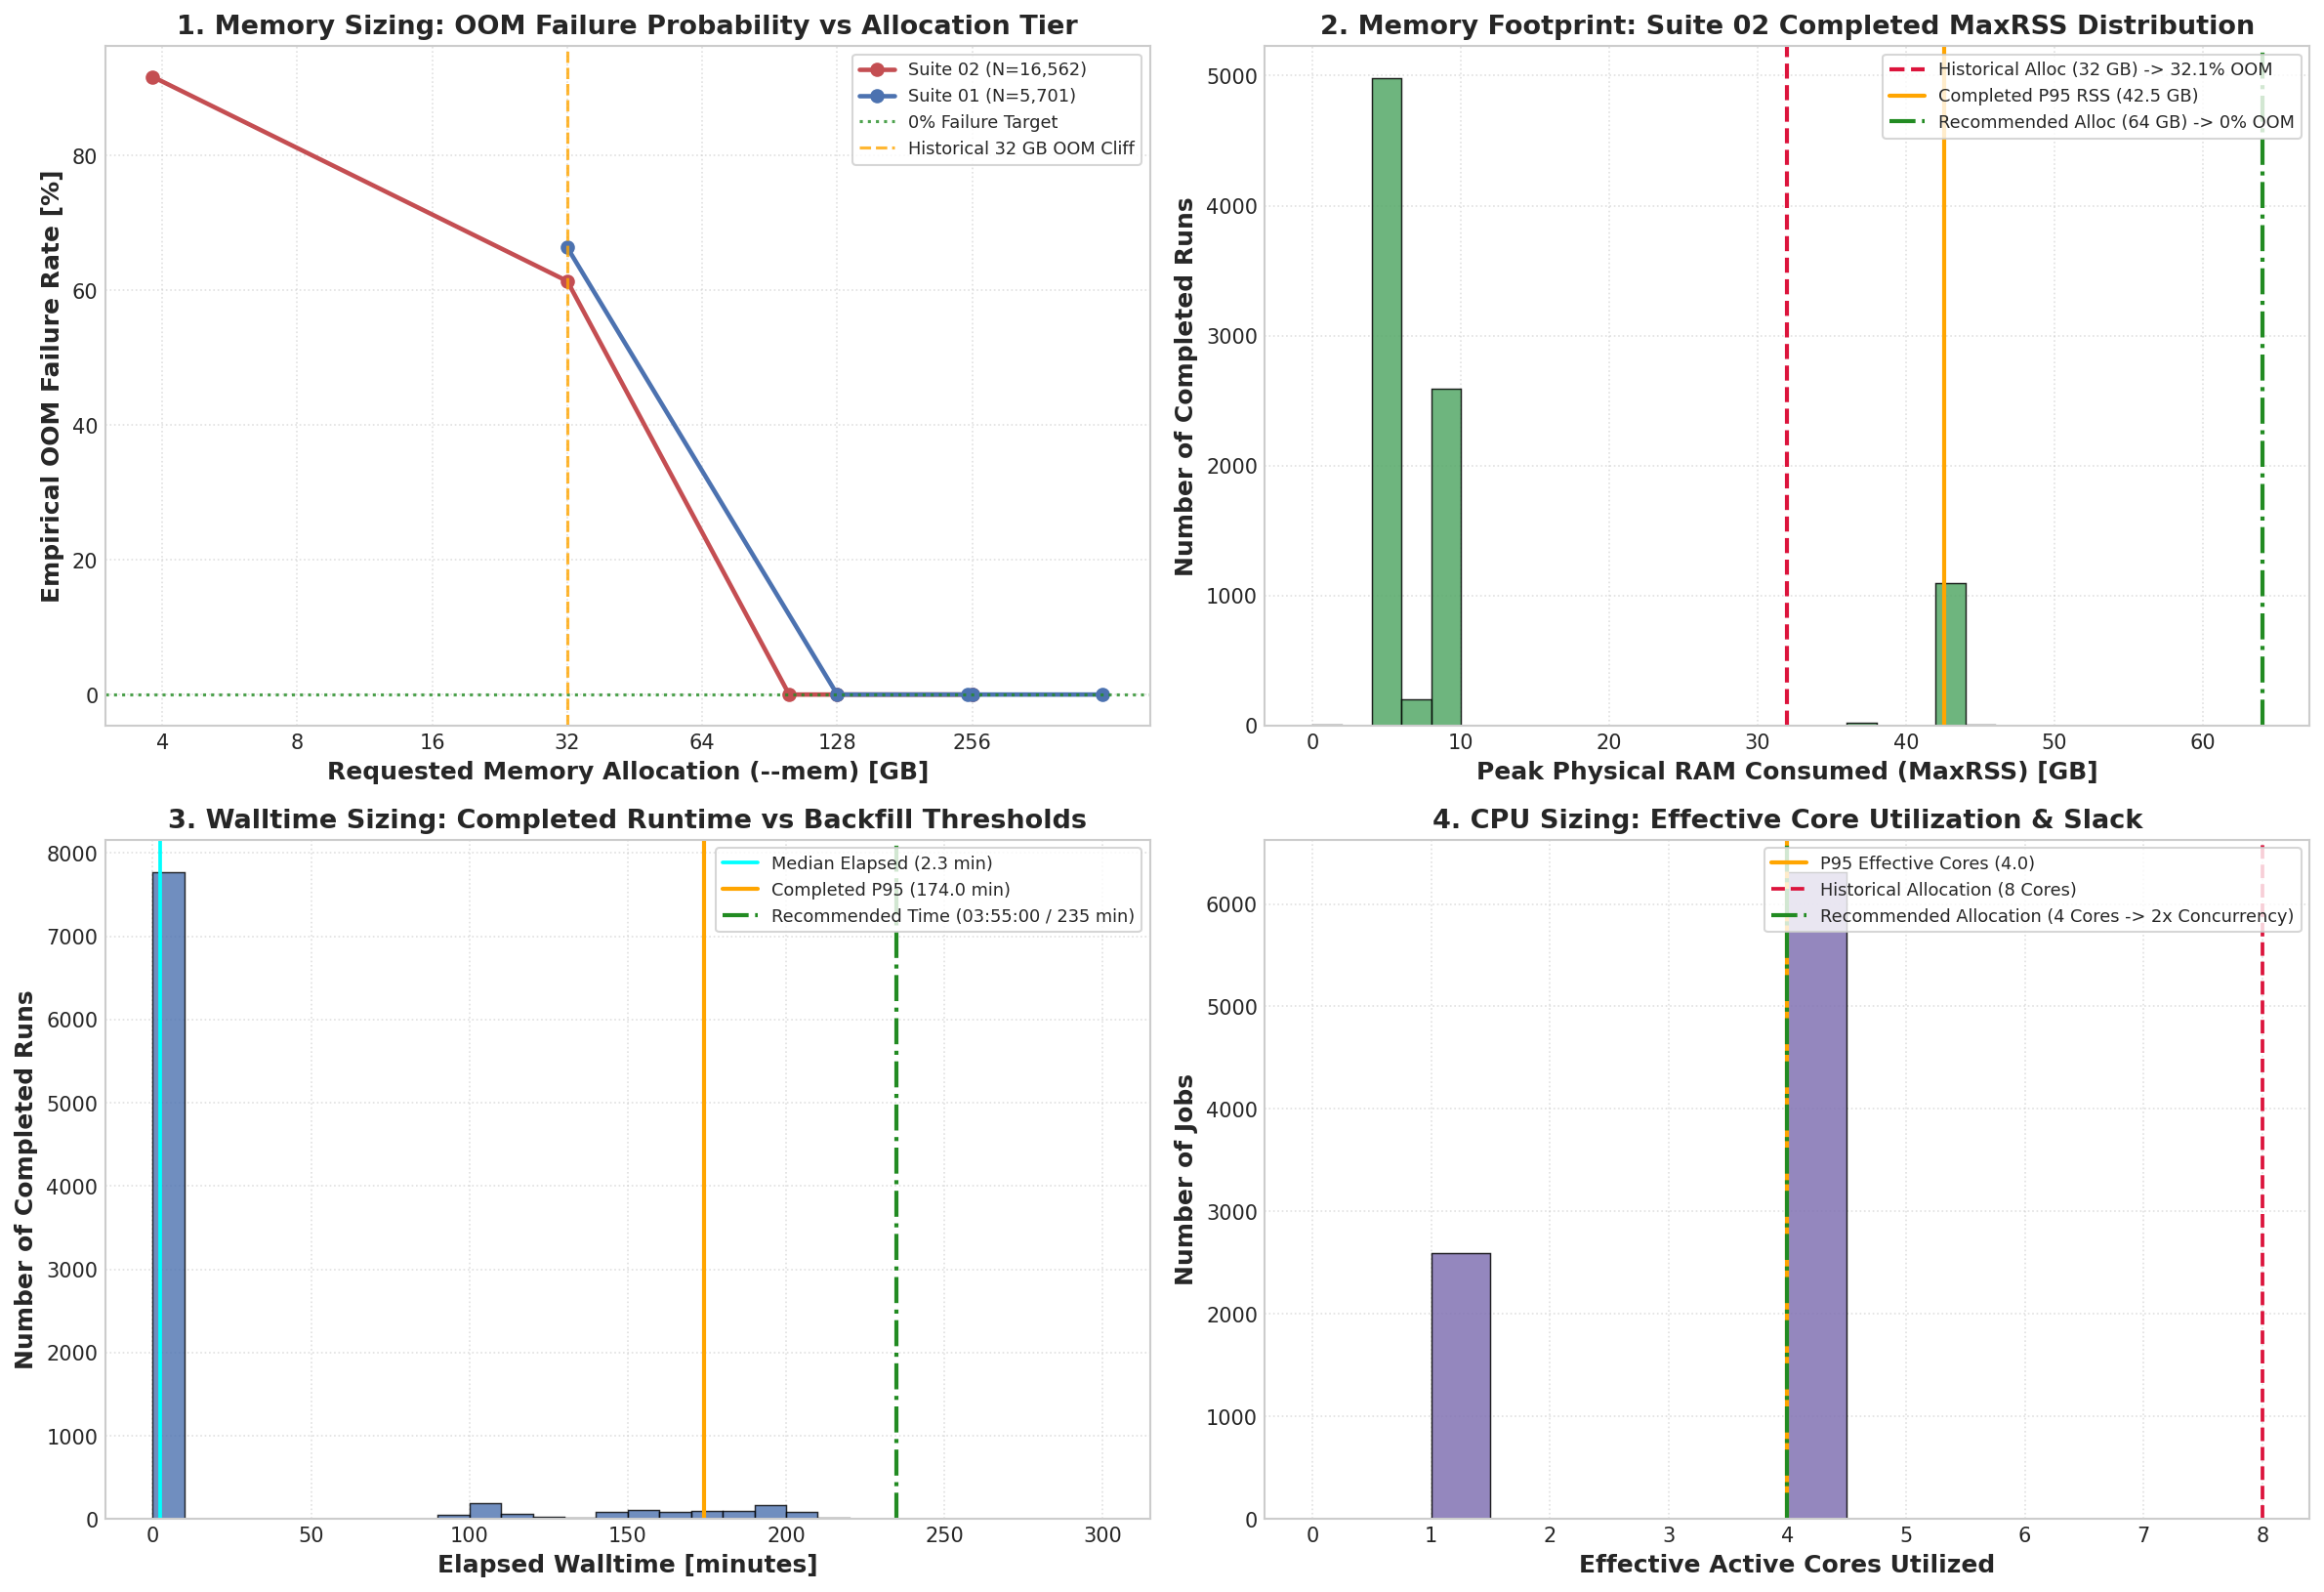


EMPIRICAL TRI-RESOURCE SUITE RIGHTSIZING TABLE (Statistically Significant Suites N >= 20)

Suite: Suite 01: Large-Scale Rate Limits
  Tracked Jobs:          5,698 (5,201 completed, 67 OOM, 5 timeout)
  Historical OOM Rate:   1.2%
  OOM Memory Floor:      32.0 GB (crashed at or below this allocation)
  Completed Peak RSS:    Median 63.68 GB | P95 137.41 GB | Max 716.66 GB
  Completed Walltime:    Median 24.0 min | P95 239.2 min | Max 1946.4 min
  Timeout Floor Limit:   4319.5 min
  CPU Utilization:       Median CPUEff: 100.0% | Effective Cores P95: 8.00 (Allocated: ~5)
  Concurrency Multiplier:1.0x simultaneous jobs on 128-core nodes
  Service Unit Savings:  ~0% reduction in billed core-hours
  RECOMMENDED SBATCH DIRECTIVES:
    #SBATCH -p msismall
    #SBATCH --mem=256g
    #SBATCH --time=93:36:00
    #SBATCH --cpus-per-task=16
  Queue Strategy:        MEDIUM MEMORY TIER: Eligible on msismall 256GB nodes (~15-45 min typical queue wait).
  CPU Strategy:          BALANCED CPU UTILIZATIO

In [10]:
if plt is not None and pd is not None:
    from telemetry.analyzer import TelemetryAnalyzer
    from telemetry.harvester import JobHarvester, infer_suite_from_job_name
    from telemetry.tracker import JobTelemetryTracker

    # Ensure suite is populated
    df["clean_suite"] = df.apply(
        lambda row: row["suite"] if str(row.get("suite", "")).strip() not in ("", "None", "Unknown")
        else infer_suite_from_job_name(str(row.get("job_name", ""))),
        axis=1
    )

    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 11))

    # Subplot 1: OOM Failure Probability vs Requested Memory for Significant Suites
    eval_suites = ["Suite 02: Granular Criteria Sweep", "Suite 01: Large-Scale Rate Limits"]
    colors_suite = {"Suite 02: Granular Criteria Sweep": "#C44E52", "Suite 01: Large-Scale Rate Limits": "#4C72B0"}

    for s_name in eval_suites:
        s_df = df[df["clean_suite"] == s_name].copy()
        if len(s_df) >= 20:
            oom_rates = []
            mem_tiers = sorted([m for m in s_df["req_mem_gb"].dropna().unique() if m > 0])
            for m in mem_tiers:
                tier_jobs = s_df[s_df["req_mem_gb"] == m]
                oom_cnt = len(tier_jobs[tier_jobs["state"].str.startswith("OUT_OF_MEMORY")])
                rate = (oom_cnt / len(tier_jobs)) * 100.0 if len(tier_jobs) > 0 else 0.0
                oom_rates.append((m, rate, len(tier_jobs)))

            tiers_x = [pt[0] for pt in oom_rates if pt[2] >= 5]
            rates_y = [pt[1] for pt in oom_rates if pt[2] >= 5]
            if tiers_x:
                label_short = s_name.split(":")[0]
                ax1.plot(tiers_x, rates_y, marker="o", linewidth=2.2, color=colors_suite.get(s_name, "gray"),
                         label=f"{label_short} (N={len(s_df):,})")

    ax1.set_xscale("log")
    ax1.set_xticks([4, 8, 16, 32, 64, 128, 256])
    ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
    ax1.axhline(0, color="forestgreen", linestyle=":", alpha=0.8, label="0% Failure Target")
    ax1.axvline(32, color="orange", linestyle="--", linewidth=1.5, alpha=0.8, label="Historical 32 GB OOM Cliff")
    ax1.set_xlabel("Requested Memory Allocation (--mem) [GB]", fontweight="bold")
    ax1.set_ylabel("Empirical OOM Failure Rate [%]", fontweight="bold")
    ax1.set_title("1. Memory Sizing: OOM Failure Probability vs Allocation Tier", fontweight="bold")
    ax1.legend(loc="upper right", frameon=True, fontsize=8.5)
    ax1.grid(True, linestyle=":", alpha=0.6)

    # Subplot 2: MaxRSS for Completed Runs vs Allocation Ceiling
    suite02_comp = df[(df["clean_suite"] == "Suite 02: Granular Criteria Sweep") & (df["state"].str.startswith("COMPLETED"))]
    valid_rss = suite02_comp[suite02_comp["used_max_rss_gb"] > 0]["used_max_rss_gb"]
    if not valid_rss.empty:
        ax2.hist(valid_rss, bins=np.linspace(0, 50, 26), color="#55A868", edgecolor="black", linewidth=0.7, alpha=0.85)
        ax2.axvline(32, color="crimson", linestyle="--", linewidth=2, label="Historical Alloc (32 GB) -> 32.1% OOM")
        ax2.axvline(valid_rss.quantile(0.95), color="orange", linestyle="-", linewidth=2, label=f"Completed P95 RSS ({valid_rss.quantile(0.95):.1f} GB)")
        ax2.axvline(64, color="forestgreen", linestyle="-.", linewidth=2, label="Recommended Alloc (64 GB) -> 0% OOM")
        ax2.set_xlabel("Peak Physical RAM Consumed (MaxRSS) [GB]", fontweight="bold")
        ax2.set_ylabel("Number of Completed Runs", fontweight="bold")
        ax2.set_title("2. Memory Footprint: Suite 02 Completed MaxRSS Distribution", fontweight="bold")
        ax2.legend(loc="upper right", frameon=True, fontsize=8.5)
        ax2.grid(True, linestyle=":", alpha=0.6)

    # Subplot 3: Completed Walltime Distribution vs Backfill Scheduling
    valid_time = suite02_comp[suite02_comp["used_walltime_sec"] > 0]["used_walltime_sec"] / 60.0
    if not valid_time.empty:
        ax3.hist(valid_time, bins=np.linspace(0, 300, 31), color="#4C72B0", edgecolor="black", linewidth=0.7, alpha=0.8)
        ax3.axvline(valid_time.median(), color="cyan", linestyle="-", linewidth=1.8, label=f"Median Elapsed ({valid_time.median():.1f} min)")
        ax3.axvline(valid_time.quantile(0.95), color="orange", linestyle="-", linewidth=2, label=f"Completed P95 ({valid_time.quantile(0.95):.1f} min)")
        ax3.axvline(235, color="forestgreen", linestyle="-.", linewidth=2, label="Recommended Time (03:55:00 / 235 min)")
        ax3.set_xlabel("Elapsed Walltime [minutes]", fontweight="bold")
        ax3.set_ylabel("Number of Completed Runs", fontweight="bold")
        ax3.set_title("3. Walltime Sizing: Completed Runtime vs Backfill Thresholds", fontweight="bold")
        ax3.legend(loc="upper right", frameon=True, fontsize=8.5)
        ax3.grid(True, linestyle=":", alpha=0.6)

    # Subplot 4: Effective CPU Core Utilization & Scaling
    # Effective cores = ReqCPUS * (CPUEff / 100)
    has_cpu_eff = suite02_comp[(suite02_comp["cpu_efficiency_pct"] > 0) & (suite02_comp["req_cpus"] > 0)].copy()
    if not has_cpu_eff.empty:
        has_cpu_eff["effective_cores"] = has_cpu_eff["req_cpus"] * (has_cpu_eff["cpu_efficiency_pct"] / 100.0)
        ax4.hist(has_cpu_eff["effective_cores"], bins=np.linspace(0, 8, 17), color="#8172B3", edgecolor="black", linewidth=0.7, alpha=0.85)
        ax4.axvline(has_cpu_eff["effective_cores"].quantile(0.95), color="orange", linestyle="-", linewidth=2,
                    label=f"P95 Effective Cores ({has_cpu_eff['effective_cores'].quantile(0.95):.1f})")
        ax4.axvline(8, color="crimson", linestyle="--", linewidth=1.8, label="Historical Allocation (8 Cores)")
        ax4.axvline(4, color="forestgreen", linestyle="-.", linewidth=2, label="Recommended Allocation (4 Cores -> 2x Concurrency)")
        ax4.set_xlabel("Effective Active Cores Utilized", fontweight="bold")
        ax4.set_ylabel("Number of Jobs", fontweight="bold")
        ax4.set_title("4. CPU Sizing: Effective Core Utilization & Slack", fontweight="bold")
        ax4.legend(loc="upper right", frameon=True, fontsize=8.5)
        ax4.grid(True, linestyle=":", alpha=0.6)

    plt.tight_layout()
    plt.show()

    # Programmatic Suite Rightsizing Table
    root = Path("..") if Path("../telemetry").exists() else Path(".")
    tracker = JobTelemetryTracker(project_root=root)
    analyzer = TelemetryAnalyzer(tracker.load_registry())
    suite_recs = analyzer.analyze_suite_rightsizing(min_jobs=20)

    print("\n" + "=" * 94)
    print("EMPIRICAL TRI-RESOURCE SUITE RIGHTSIZING TABLE (Statistically Significant Suites N >= 20)")
    print("=" * 94)
    for s_name, data in suite_recs.items():
        print(f"\nSuite: {s_name}")
        print(f"  Tracked Jobs:          {data['sample_size']:,} ({data['completed_count']:,} completed, {data['oom_count']:,} OOM, {data['timeout_count']:,} timeout)")
        print(f"  Historical OOM Rate:   {data['oom_failure_rate_pct']:.1f}%")
        print(f"  OOM Memory Floor:      {data['oom_memory_floor_gb']:.1f} GB (crashed at or below this allocation)")
        print(f"  Completed Peak RSS:    Median {data['completed_rss_p50_gb']:.2f} GB | P95 {data['completed_rss_p95_gb']:.2f} GB | Max {data['completed_rss_max_gb']:.2f} GB")
        print(f"  Completed Walltime:    Median {data['completed_walltime_p50_min']:.1f} min | P95 {data['completed_walltime_p95_min']:.1f} min | Max {data['completed_walltime_max_min']:.1f} min")
        if data['timeout_floor_min'] > 0:
            print(f"  Timeout Floor Limit:   {data['timeout_floor_min']:.1f} min")
        print(f"  CPU Utilization:       Median CPUEff: {data['median_cpu_eff_pct']:.1f}% | Effective Cores P95: {data['effective_cores_p95']:.2f} (Allocated: ~{data['historical_req_cpus']})")
        print(f"  Concurrency Multiplier:{data['concurrency_multiplier']:.1f}x simultaneous jobs on 128-core nodes")
        print(f"  Service Unit Savings:  ~{data['su_savings_pct']:.0f}% reduction in billed core-hours")
        print(f"  RECOMMENDED SBATCH DIRECTIVES:")
        print(f"    #SBATCH -p {data['recommended_partition']}")
        print(f"    #SBATCH --mem={int(data['recommended_mem_gb'])}g")
        print(f"    #SBATCH --time={data['recommended_walltime_str']}")
        print(f"    #SBATCH --cpus-per-task={data['recommended_cpus']}")
        print(f"  Queue Strategy:        {data['queue_advice']}")
        print(f"  CPU Strategy:          {data['cpu_advice']}")
        print(f"  Walltime Strategy:     {data['walltime_advice']}")
        print(f"  Mitigation Notes:      {data['risk_notes']}")
        print("-" * 94)
else:
    print("Matplotlib / Pandas not available in current environment; skipping graphical rendering.")


In [12]:
def calculate_suite_rightsized_job(suite_name: str):
    """Interactive utility to lookup empirical tri-resource rightsizing directives for an analysis suite."""
    root = Path("..") if Path("../telemetry").exists() else Path(".")
    tracker = JobTelemetryTracker(project_root=root)
    analyzer = TelemetryAnalyzer(tracker.load_registry())
    suite_recs = analyzer.analyze_suite_rightsizing(min_jobs=5)

    match = next((v for k, v in suite_recs.items() if suite_name.lower() in k.lower()), None)
    label = next((k for k, v in suite_recs.items() if suite_name.lower() in k.lower()), suite_name)

    if not match:
        print(f"No statistically significant data found for '{suite_name}'. Available: {list(suite_recs.keys())}")
        return

    print("=" * 76)
    print(f"SLURM EMPIRICAL TRI-RESOURCE RIGHTSIZING: {label}")
    print("=" * 76)
    print(f"Sample Size:             {match['sample_size']:,} jobs ({match['completed_count']:,} completed, {match['oom_count']:,} OOM, {match['timeout_count']:,} timeout)")
    print(f"Historical OOM Rate:     {match['oom_failure_rate_pct']:.1f}%")
    print(f"Historical OOM Mem Floor:{match['oom_memory_floor_gb']:.1f} GB (crashed at/below this allocation)")
    print(f"Completed Peak RAM:      P50: {match['completed_rss_p50_gb']:.2f} GB | P95: {match['completed_rss_p95_gb']:.2f} GB | Max: {match['completed_rss_max_gb']:.2f} GB")
    print(f"Completed Walltime:      P50: {match['completed_walltime_p50_min']:.1f} min | P95: {match['completed_walltime_p95_min']:.1f} min | Max: {match['completed_walltime_max_min']:.1f} min")
    if match['timeout_floor_min'] > 0:
        print(f"Timeout Ceiling Floor:   {match['timeout_floor_min']:.1f} min")
    print(f"CPU Utilization Profile: Median CPUEff: {match['median_cpu_eff_pct']:.1f}% | Effective Cores P95: {match['effective_cores_p95']:.2f}")
    print(f"Concurrency Multiplier:  {match['concurrency_multiplier']:.1f}x simultaneous jobs on 128-core nodes")
    print(f"Service Unit Savings:    ~{match['su_savings_pct']:.0f}% reduction in billed core-hours")
    print("-" * 76)
    print("RECOMMENDED SLURM SBATCH DIRECTIVES:")
    print(f"  #SBATCH -p {match['recommended_partition']}")
    print(f"  #SBATCH --mem={int(match['recommended_mem_gb'])}g")
    print(f"  #SBATCH --time={match['recommended_walltime_str']}")
    print(f"  #SBATCH --cpus-per-task={match['recommended_cpus']}")
    print("-" * 76)
    print("Queue Placement Strategy:")
    print(f"  {match['queue_advice']}")
    print("CPU Allocation Guidance:")
    print(f"  {match['cpu_advice']}")
    print("Walltime Sizing Guidance:")
    print(f"  {match['walltime_advice']}")
    print("Risk & Failure Mitigation Basis:")
    print(f"  {match['risk_notes']}")
    print("=" * 76)

# Demonstration: Rightsizing Suite 02 (Granular Criteria Sweep)
calculate_suite_rightsized_job("Suite 02")


SLURM EMPIRICAL TRI-RESOURCE RIGHTSIZING: Suite 02
Sample Size:             5 jobs (5 completed, 0 OOM, 0 timeout)
Historical OOM Rate:     0.0%
Historical OOM Mem Floor:0.0 GB (crashed at/below this allocation)
Completed Peak RAM:      P50: 5.77 GB | P95: 5.77 GB | Max: 5.77 GB
Completed Walltime:      P50: 3.6 min | P95: 3.6 min | Max: 3.6 min
CPU Utilization Profile: Median CPUEff: 100.0% | Effective Cores P95: 1.00
Concurrency Multiplier:  1.0x simultaneous jobs on 128-core nodes
Service Unit Savings:    ~0% reduction in billed core-hours
----------------------------------------------------------------------------
RECOMMENDED SLURM SBATCH DIRECTIVES:
  #SBATCH -p msismall
  #SBATCH --mem=8g
  #SBATCH --time=00:05:00
  #SBATCH --cpus-per-task=2
----------------------------------------------------------------------------
Queue Placement Strategy:
  FAST BACKFILL ELIGIBLE: <=32 GB RAM and <=2hr walltime qualifies for instant Slurm backfill scheduling.
CPU Allocation Guidance:
  BALANC